In [38]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import keras

import tensorflow as tf
from tensorflow.keras.models import Sequential, load_model
from tensorflow.keras.layers import Dense, Flatten, Input
from tensorflow.keras.utils import image_dataset_from_directory
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from keras.callbacks import EarlyStopping
from keras.layers import Input, Activation, Flatten
from keras.utils import to_categorical

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, ConfusionMatrixDisplay


In [22]:
import random

SEED_VALUE = 42
random.seed(SEED_VALUE)
np.random.seed(SEED_VALUE)
tf.random.set_seed(SEED_VALUE)

In [23]:
IMG_HEIGHT = 48
IMG_WIDTH = 48
BATCH_SIZE = 32

train_dataset = keras.utils.image_dataset_from_directory(
    'train',
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    color_mode='rgb',
    batch_size=BATCH_SIZE,

)

test_dataset = keras.utils.image_dataset_from_directory(
    'test',
    image_size=(IMG_HEIGHT, IMG_WIDTH),
    color_mode='rgb',
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 28709 files belonging to 7 classes.
Found 7178 files belonging to 7 classes.


In [24]:
train_dataset.class_names

['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']

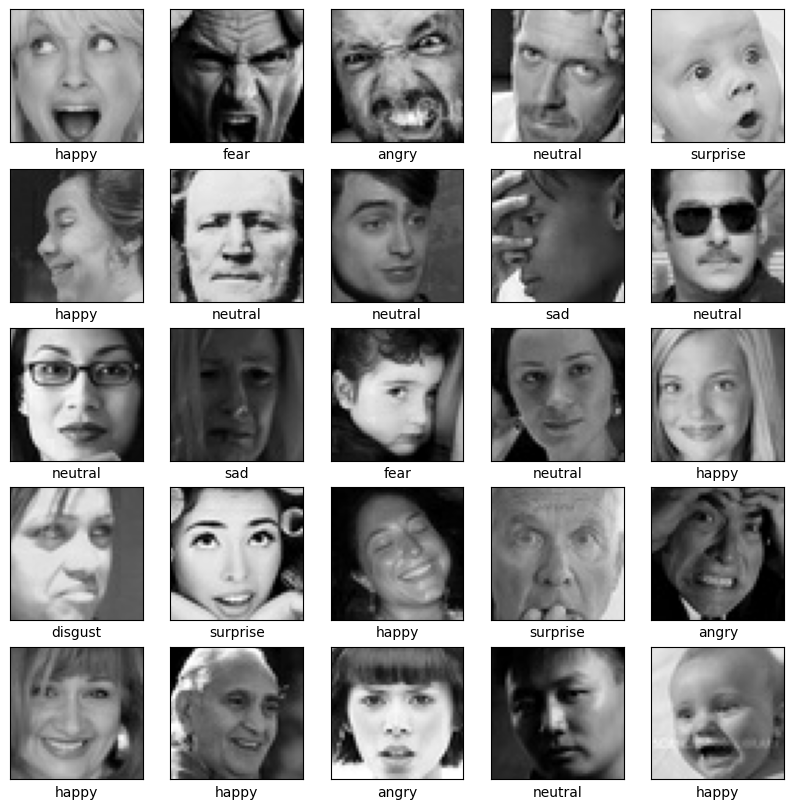

In [25]:
X_train_list, y_train_list = [], []
for images, labels in train_dataset:
    X_train_list.append(images.numpy())
    y_train_list.append(labels.numpy())

X_train = np.concatenate(X_train_list)
y_train = np.concatenate(y_train_list)

class_names = train_dataset.class_names

plt.figure(figsize=(10, 10))
for i in range(25):
    plt.subplot(5, 5, i + 1)
    plt.imshow(X_train[i].astype("uint8"))
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.xlabel(class_names[y_train[i]])
plt.show()

In [26]:
X_test_list, y_test_list = [], []
for images, labels in test_dataset:
    X_test_list.append(images.numpy())
    y_test_list.append(labels.numpy())

X_test = np.concatenate(X_test_list)
y_test = np.concatenate(y_test_list)

# قسمنا على 255 عشان نصغر الأقيم وتصير بين 0 و 1
X_train = X_train / 255
X_test = X_test / 255

In [46]:
model = Sequential([
    Flatten(input_shape=(IMG_HEIGHT, IMG_WIDTH, 3)),
    Dense(128, activation='relu'),
    Dense(len(class_names), activation='softmax')
])

model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_5 (Flatten)                  │ (None, 6912)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_8 (Dense)                      │ (None, 128)                 │         884,864 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_9 (Dense)                      │ (None, 7)                   │             903 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 885,767 (3.38 MB)

 Trainable params: 885,767 (3.38 MB)

 Non-trainable params: 0 (0.00 B)

In [48]:
EPOCHS = 10
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=EPOCHS
)

Epoch 1/10
898/898 ━━━━━━━━━━━━━━━━━━━━ 16s 15ms/step - accuracy: 0.2672 - loss: 1.8352 - val_accuracy: 0.2736 - val_loss: 1.7745
Epoch 2/10
898/898 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.3100 - loss: 1.7247 - val_accuracy: 0.3153 - val_loss: 1.7136
Epoch 3/10
898/898 ━━━━━━━━━━━━━━━━━━━━ 16s 18ms/step - accuracy: 0.3259 - loss: 1.6967 - val_accuracy: 0.3246 - val_loss: 1.6903
Epoch 4/10
898/898 ━━━━━━━━━━━━━━━━━━━━ 20s 22ms/step - accuracy: 0.3378 - loss: 1.6807 - val_accuracy: 0.3427 - val_loss: 1.6684
Epoch 5/10
898/898 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.3430 - loss: 1.6694 - val_accuracy: 0.3475 - val_loss: 1.6655
Epoch 6/10
898/898 ━━━━━━━━━━━━━━━━━━━━ 19s 21ms/step - accuracy: 0.3459 - loss: 1.6620 - val_accuracy: 0.3572 - val_loss: 1.6573
Epoch 7/10
898/898 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.3490 - loss: 1.6549 - val_accuracy: 0.3608 - val_loss: 1.6526
Epoch 8/10
898/898 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.3518 - loss: 1.6490 - 

In [49]:
EPOCHS = 20
history = model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=EPOCHS
)

Epoch 1/20
898/898 ━━━━━━━━━━━━━━━━━━━━ 14s 15ms/step - accuracy: 0.3585 - loss: 1.6380 - val_accuracy: 0.3555 - val_loss: 1.6582
Epoch 2/20
898/898 ━━━━━━━━━━━━━━━━━━━━ 13s 14ms/step - accuracy: 0.3615 - loss: 1.6332 - val_accuracy: 0.3550 - val_loss: 1.6586
Epoch 3/20
898/898 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.3611 - loss: 1.6325 - val_accuracy: 0.3532 - val_loss: 1.6580
Epoch 4/20
898/898 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.3622 - loss: 1.6296 - val_accuracy: 0.3582 - val_loss: 1.6520
Epoch 5/20
898/898 ━━━━━━━━━━━━━━━━━━━━ 12s 13ms/step - accuracy: 0.3637 - loss: 1.6265 - val_accuracy: 0.3578 - val_loss: 1.6537
Epoch 6/20
898/898 ━━━━━━━━━━━━━━━━━━━━ 15s 16ms/step - accuracy: 0.3640 - loss: 1.6246 - val_accuracy: 0.3572 - val_loss: 1.6488
Epoch 7/20
898/898 ━━━━━━━━━━━━━━━━━━━━ 18s 20ms/step - accuracy: 0.3657 - loss: 1.6221 - val_accuracy: 0.3605 - val_loss: 1.6510
Epoch 8/20
898/898 ━━━━━━━━━━━━━━━━━━━━ 24s 27ms/step - accuracy: 0.3656 - loss: 1.6195 - 

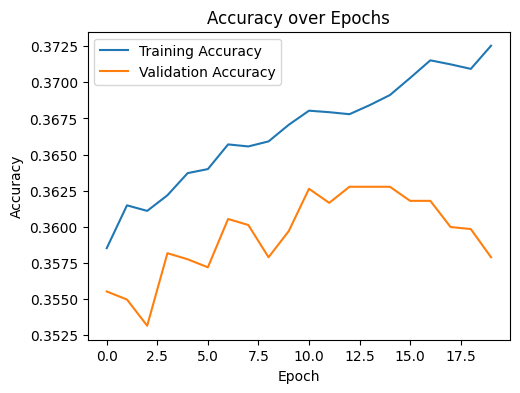

In [59]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()


In [51]:
test_loss, test_acc = model.evaluate(X_test, y_test)

print(f"Test Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.3579 - loss: 1.6529
Test Accuracy: 35.79%
Test Loss: 1.6529


225/225 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step


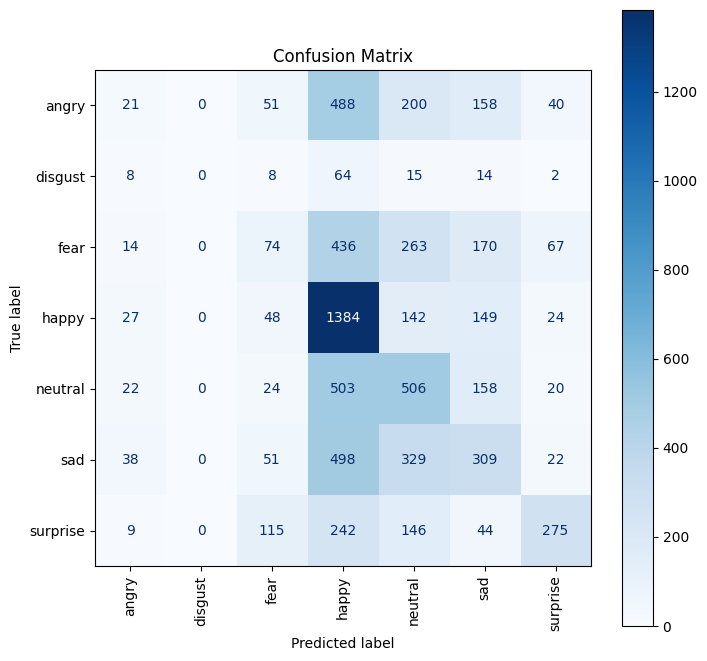

In [52]:
y_pred = model.predict(X_test)
y_pred_classes = np.argmax(y_pred, axis=1)

cm = confusion_matrix(y_test, y_pred_classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)

plt.figure(figsize=(8, 8))
disp.plot(cmap=plt.cm.Blues, ax=plt.gca(), xticks_rotation='vertical')
plt.title("Confusion Matrix")
plt.show()

In [53]:
# Save the trained model in h5 format
model.save("emotion_recognition_model.h5")
print("Model saved successfully!")

Model saved successfully!


In [54]:
model.save("emotion_recognition_model.keras")
print("Model saved successfully!")

Model saved successfully!


In [55]:
loaded_model = load_model("emotion_recognition_model.keras")
print("Model loaded successfully!")

Model loaded successfully!


C:\Users\Nebras-PC\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\saving\saving_lib.py:869: UserWarning: Skipping variable loading for optimizer 'rm_sprop', because it has 6 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(store)


In [56]:
from tensorflow.keras.models import load_model

# Load the model without the optimizer state (cleaner for evaluation/inference)
loaded_model = load_model("emotion_recognition_model.keras", compile=False)
print("Model loaded successfully without warnings!")

Model loaded successfully without warnings!
